# 10 · Screenshots: size, scaling and token cost
Level L2 · Part 2 · core · ~30 min · builds on 02, 07

## Goal
By the end you can take a Playwright screenshot of Pocket Tracker at a chosen viewport, compute its image-token cost with the Claude, OpenAI and Gemini formulas, downscale it to fit a token budget, and say how many bytes it adds to a recorded cassette.

## The idea
In lesson 02 you learned that a screenshot's token cost depends on its pixel size, not on what is drawn. In Playwright the pixel size is set by the **viewport**: the visible area of the page, in CSS pixels (the page's own pixel unit), that you choose when you create a browser context. A bigger viewport costs more **image tokens** per step, even when it shows the same issues. Every vendor counts image tokens differently, and each one caps the size it accepts. **Downscaling** (resizing the image before you send it) keeps you under the cap and under your budget, at the price of smaller text.

Analogy: posting a photo of a whiteboard. A wider photo costs more postage, even if half of it is empty wall.

## Picture
```mermaid
flowchart LR
  V["viewport<br/>1024x768 or 1920x1080"] --> S["page.screenshot()<br/>PNG / JPEG"]
  S --> T["image tokens<br/>vendor formula"]
  S --> D["downscale<br/>Pillow resize"]
  D --> T
  S --> C["cassette bytes<br/>base64 (text encoding of bytes) per step"]
```

## Step by step

### 1. Start Pocket Tracker
Same as lessons 07–09: copy the app to a scratch folder, start uvicorn on a free port, poll `/health`.

In [1]:
import atexit, base64, io, json, math, os, shutil, socket, subprocess, sys, time
from pathlib import Path
import httpx
from IPython.display import display
from PIL import Image
from playwright.async_api import async_playwright   # Playwright's async API, as in lesson 07

Copy the app, pick a free port, start the server and wait until it answers.

In [2]:
WORK, REPO = Path("../work/10"), Path("../work/10/pocket_tracker")
shutil.rmtree(WORK, ignore_errors=True)
shutil.copytree("../apps/pocket_tracker", REPO, ignore=shutil.ignore_patterns("*.db", "__pycache__", ".pytest_cache"))
with socket.socket() as s:
    s.bind(("127.0.0.1", 0))
    PORT = s.getsockname()[1]
BASE = f"http://127.0.0.1:{PORT}"
env = {**os.environ, "POCKET_TRACKER_DB": str((WORK / "pocket_tracker.db").resolve())}
log = open(WORK / "server.log", "w")
server = subprocess.Popen([sys.executable, "-m", "uvicorn", "app:app", "--host", "127.0.0.1",
                           "--port", str(PORT)], cwd=REPO, env=env, stdout=log, stderr=log)
atexit.register(server.terminate)
deadline = time.time() + 15
while True:
    try:
        print("health:", httpx.get(f"{BASE}/health").json()); break
    except httpx.ConnectError:
        if time.time() > deadline or server.poll() is not None:
            raise RuntimeError("server did not start; see ../work/10/server.log")
        time.sleep(0.2)

health: {'status': 'ok'}


### 2. Browser and fallback
Browser cells are tagged `needs-download`. When they are skipped, `seen` and the PNG files come from the **recorded output** of a real run in `../data/recorded/` (`10.json` plus two PNGs), so every later cell still works on real screenshots.

In [3]:
out = subprocess.run([sys.executable, "-m", "playwright", "install", "chromium"], capture_output=True, text=True)
print("playwright install chromium -> exit code", out.returncode)

⏭  Skipped: this cell needs [download]. Run it yourself, or re-run with TUT_ENABLE=download.


Load the recording as the starting value of `seen`; live cells overwrite it.

In [4]:
REC = Path("../data/recorded")
REC_PATH = REC / "10.json"
seen = json.loads(REC_PATH.read_text()) if REC_PATH.exists() else {}
seen["source"] = "recorded output (real run, saved earlier)"
shots = {name: REC / f"10_issues_{name}.png" for name in ["1024x768", "1920x1080"]}
print("fallback keys:", sorted(k for k in seen if k != "source"))

fallback keys: ['1024x768', '1920x1080']


### 3. Screenshot at two viewports
`new_context(viewport=...)` sets the page size in CSS pixels. `page.screenshot()` captures the viewport only (not the whole scrollable page) and returns PNG bytes. We also take a JPEG at quality 60 of the same view, to compare file sizes later.

In [5]:
async with async_playwright() as p:
    browser = await p.chromium.launch()
    for name in shots:
        w, h = map(int, name.split("x"))
        page = await (await browser.new_context(viewport={"width": w, "height": h})).new_page()
        await page.goto(f"{BASE}/issues")
        png = await page.screenshot()
        jpg = await page.screenshot(type="jpeg", quality=60)
        shots[name] = WORK / f"10_issues_{name}.png"
        shots[name].write_bytes(png)
        seen[name] = {"png_size": list(Image.open(io.BytesIO(png)).size), "png_bytes": len(png),
                      "jpeg60_bytes": len(jpg), "rows_visible": await page.locator("tbody tr").count()}
    await browser.close()
seen["source"] = "live run"
print({k: v for k, v in seen.items() if k != "source"})

⏭  Skipped: this cell needs [download]. Run it yourself, or re-run with TUT_ENABLE=download.


What came back, for each viewport:

In [6]:
print(f"[{seen['source']}]")
for name in shots:
    s = seen[name]
    print(f"viewport {name:9}: image {s['png_size'][0]}x{s['png_size'][1]} px, "
          f"{s['rows_visible']} issue rows, PNG {s['png_bytes']:,} B, JPEG q60 {s['jpeg60_bytes']:,} B")

[recorded output (real run, saved earlier)]
viewport 1024x768 : image 1024x768 px, 10 issue rows, PNG 76,104 B, JPEG q60 55,733 B
viewport 1920x1080: image 1920x1080 px, 10 issue rows, PNG 83,059 B, JPEG q60 67,449 B


The image is exactly the viewport size (at the default device scale of 1; lesson 11 covers 2x screens). Both views show the same ten issue rows: the bigger one only adds empty margin.

Look at the large one, scaled down for display only:

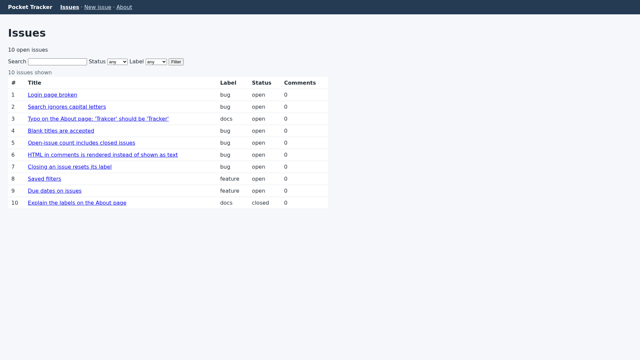

In [7]:
big = Image.open(shots["1920x1080"])
display(big.resize((640, 360)))

### 4. Image tokens: three vendor formulas
Each vendor turns pixels into tokens its own way (all from the vendors' docs, October 2026, as summarised in RESEARCH.md; we compute them below, we do not measure them against the APIs):
- **Claude**: one token per 28x28 patch, `ceil(w/28) * ceil(h/28)`. Claude 4.7 and later accept up to 2576 px on the long edge and 4784 tokens; older models 1568 px and 1568 tokens. Larger images are shrunk first.
- **OpenAI** (`gpt-6-astra`, `detail: "high"`): 32x32 patches, at most 2,500 (larger images are shrunk), times a 1.2 multiplier (on gpt-6-astra the default `auto` means `original`; set `detail: "high"` to get this budget).
- **Gemini 3**: a flat count per image set by `media_resolution`; the default is 1120 tokens, whatever the size.

In [8]:
def claude_tokens(w, h):
    return math.ceil(w / 28) * math.ceil(h / 28)

def openai_tokens(w, h, budget=2500, multiplier=1.2):
    patches = math.ceil(w / 32) * math.ceil(h / 32)
    if patches > budget:                                # shrink proportionally, round down, recount
        scale = math.sqrt(budget / patches)
        w, h = int(w * scale), int(h * scale)
        patches = math.ceil(w / 32) * math.ceil(h / 32)
    return math.ceil(patches * multiplier)

def gemini3_tokens(w, h, media_resolution="default"):
    return {"low": 280, "medium": 560, "default": 1120, "high": 1120, "ultra_high": 2240}[media_resolution]

print(claude_tokens(1024, 768), openai_tokens(1024, 1024), openai_tokens(2048, 2048))

1036 1229 3000


Sanity check against the docs' own examples: OpenAI lists 1024x1024 → 1229 and 2048x2048 → 3000, and 1024x768 → 1036 for Claude is the number lesson 08 measured on the New issue page. Same viewport, same cost, whichever page is open.

Now the two screenshots:

In [9]:
print(f"{'viewport':10} {'Claude 4.7+':>11} {'OpenAI':>7} {'Gemini 3':>9}")
cost = {}
for name in shots:
    w, h = seen[name]["png_size"]
    cost[name] = {"claude": claude_tokens(w, h), "openai": openai_tokens(w, h), "gemini": gemini3_tokens(w, h)}
    print(f"{name:10} {cost[name]['claude']:>11} {cost[name]['openai']:>7} {cost[name]['gemini']:>9}")
print(f"1920x1080 costs {cost['1920x1080']['claude'] / cost['1024x768']['claude']:.1f}x more on Claude")

viewport   Claude 4.7+  OpenAI  Gemini 3
1024x768          1036     922      1120
1920x1080         2691    2448      1120
1920x1080 costs 2.6x more on Claude


On Claude and OpenAI the big viewport costs about 2.6x more for the same ten rows. Gemini charges a flat 1120 either way. The docs set the cost by `media_resolution`, not by size, so a bigger image does not cost more, but you cannot tell how much detail the model keeps. Over a 30-step run, 1024x768 instead of 1920x1080 saves about 50,000 Claude tokens.

### 5. Downscaling to the model's limits
Claude's docs give a reference function for the size it shrinks an image to: the largest same-shape size that fits both the edge limit and the token limit. We copy it as published.

In [10]:
def resized_size(width, height, max_edge=1568, max_tokens=1568):
    """Claude's reference implementation (vision-coordinates docs): the size Claude resizes to."""
    def fits(w, h):
        return (math.ceil(w / 28) * 28 <= max_edge and math.ceil(h / 28) * 28 <= max_edge
                and claude_tokens(w, h) <= max_tokens)
    if fits(width, height):
        return (width, height)
    if height > width:
        rh, rw = resized_size(height, width, max_edge, max_tokens)
        return (rw, rh)
    aspect, lo, hi = width / height, 1, width          # binary search on the long edge
    while lo + 1 < hi:
        mid = (lo + hi) // 2
        lo, hi = (mid, hi) if fits(mid, max(round(mid / aspect), 1)) else (lo, mid)
    return (lo, max(round(lo / aspect), 1))

TIERS = {"standard (older models)": (1568, 1568), "high-res (Claude 4.7+)": (2576, 4784)}
for tier, (edge, tok) in TIERS.items():
    size = resized_size(1920, 1080, edge, tok)
    print(f"1920x1080 on {tier:24} -> {size[0]}x{size[1]}, {claude_tokens(*size)} tokens")

1920x1080 on standard (older models)  -> 1456x819, 1560 tokens
1920x1080 on high-res (Claude 4.7+)   -> 1920x1080, 2691 tokens


On an older model the 1920x1080 screenshot would be shrunk to 1456x819 (1560 tokens); on a current one it fits as is (2691 tokens). For screenshots returned to Claude's computer-use tool the API does **not** shrink: it rejects oversized images, so the harness must resize first (lesson 13).

Pick your own budget instead: here, at most 800 tokens per screenshot. Resize with Pillow's `LANCZOS` filter, which keeps text sharper than the default.

In [11]:
target = resized_size(*big.size, max_edge=2576, max_tokens=800)
small = big.resize(target, Image.LANCZOS)
small.save(WORK / "10_issues_small.png")
print("downscaled to", small.size, "->", claude_tokens(*small.size), "Claude tokens,",
      openai_tokens(*small.size), "OpenAI tokens")

downscaled to (1046, 588) -> 798 Claude tokens, 753 OpenAI tokens


Compare the same corner of the page, original and downscaled, at the size each model would see:

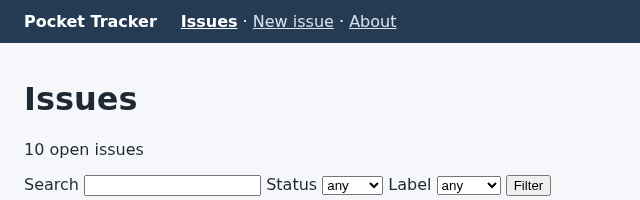

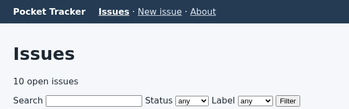

same region: (640, 200) -> (349, 109) pixels


In [12]:
box = (0, 0, 640, 200)                                   # top-left corner of the original
scale = small.size[0] / big.size[0]
crop_small = small.crop(tuple(round(c * scale) for c in box))
display(big.crop(box))
display(crop_small)
print("same region:", big.crop(box).size, "->", crop_small.size, "pixels")

The downscaled text is smaller and softer but still readable. That is the trade-off: fewer tokens until the labels the model must read blur. Text shrinks with every downscale; a 1024x768 viewport avoids the problem by never making the big image.

### 6. Cassette size: bytes, not tokens
Recorded runs (`llm_replay` cassettes, from lesson 05) store every request, and an image travels as **base64** text, 4/3 of its file size. In an agent loop each request resends the whole history, so step `k` carries `k` screenshots.

In [13]:
def b64_kb(n_bytes):
    return len(base64.b64encode(b"\0" * n_bytes)) / 1024

small_png = (WORK / "10_issues_small.png").stat().st_size
options = {"1920x1080 PNG": seen["1920x1080"]["png_bytes"], "1024x768 PNG": seen["1024x768"]["png_bytes"],
           "1024x768 JPEG q60": seen["1024x768"]["jpeg60_bytes"], f"{small.size[0]}x{small.size[1]} PNG": small_png}
steps = 10
print(f"{'image':20} {'base64/step':>12} {'10-step cassette':>17}")
for name, n in options.items():
    print(f"{name:20} {b64_kb(n):>9.1f} KB {b64_kb(n) * steps * (steps + 1) / 2 / 1024:>14.2f} MB")

image                 base64/step  10-step cassette
1920x1080 PNG            108.2 KB           5.81 MB
1024x768 PNG              99.1 KB           5.32 MB
1024x768 JPEG q60         72.6 KB           3.90 MB
1046x588 PNG              87.6 KB           4.70 MB


Ten steps store 1+2+…+10 = 55 copies of the screenshot: about 5 MB for one short recorded run. Two surprises:
- The 1920x1080 PNG is barely bigger than the 1024x768 one: the extra area is empty margin, which PNG compresses to almost nothing. Tokens grew 2.6x, bytes 9%.
- JPEG at quality 60 saves about a quarter of the bytes, but adds blur around text. Tokens do not change: only width and height count.

Real sites with photos are many times larger. The levers, in order: small viewport, few recorded steps, an aria snapshot as the main observation (lesson 08).

The last browser cell saves this run as the recording: the JSON numbers and the two PNGs.

In [14]:
REC.mkdir(parents=True, exist_ok=True)
REC_PATH.write_text(json.dumps({k: v for k, v in seen.items() if k != "source"}, indent=1) + "\n")
for name, path in shots.items():
    shutil.copy(path, REC / f"10_issues_{name}.png")
print("saved", REC_PATH, "and", [f"10_issues_{n}.png" for n in shots])

⏭  Skipped: this cell needs [download]. Run it yourself, or re-run with TUT_ENABLE=download.


## At work
- Vendors recommend small viewports for computer use (1024x768 or 1280x720) → lesson 11.
- Claude's computer-use and browser-use tools reject an oversized screenshot instead of shrinking it, so the harness resizes and maps clicks back → lessons 11 and 13.
- Claude's docs put a screenshot at roughly 1,000–1,800 input tokens (our 1024x768 = 1036, 1920x1080 = 2691). Past 20 images in one request the per-image limit drops to 2000 px per side, so teams prune old images and use prompt caching to keep long runs affordable → lesson 43.
- Every vendor counts differently (Claude 28 px patches, OpenAI 32 px patches with a cap, Gemini a flat per-image count), so cost dashboards that assume one formula are wrong after a model switch → lesson 13a (OpenAI and Gemini tools).
- Teams store a screenshot per step with the action log and a Playwright trace; storage grows with steps x image size → lesson 54.

## What just happened
- The **viewport** you set in `new_context` fixed the screenshot's pixel size: 1024x768 and 1920x1080 showed the same ten issues.
- You computed **image tokens** with three vendor formulas: the big viewport cost about 2.6x more on Claude and OpenAI; Gemini 3 charged a flat 1120.
- Claude's reference `resized_size` showed where an image is shrunk (1920x1080 → 1456x819 on older models) and let you pick your own budget.
- **Downscaling** with Pillow cut tokens and made text smaller.
- A cassette stores each screenshot as base64, once per later step, so viewport and step count drive its size.

## Common mistakes
Downscaling to the edge limit alone. A 1920x1080 screenshot shrunk so its long edge is 1568 px looks safe, but it breaks the token limit of a standard-tier model. `check_tool_screenshot` is our own imitation of the rejection that Claude's computer-use tool returns for an oversized image (docs: such images are rejected, not resized). The real API error text differs; for ordinary images, the request option `transformations: {"oversized_image": "error"}` makes the API return a real 400 error instead of resizing silently.

In [15]:
def check_tool_screenshot(w, h, max_edge=1568, max_tokens=1568):
    if resized_size(w, h, max_edge, max_tokens) != (w, h):
        raise ValueError(f"screenshot {w}x{h} = {claude_tokens(w, h)} tokens exceeds the model limit; "
                         f"resize to {resized_size(w, h, max_edge, max_tokens)} first")
    return "ok"

thumb = big.copy()
thumb.thumbnail((1568, 1568))              # only caps the edges: 1568x882
check_tool_screenshot(*thumb.size)

ValueError: screenshot 1568x882 = 1792 tokens exceeds the model limit; resize to (1456, 819) first

Fix: compute the target with `resized_size` (edge **and** token limits) and resize to exactly that.

In [16]:
fixed = big.resize(resized_size(*big.size), Image.LANCZOS)
print(fixed.size, claude_tokens(*fixed.size), "tokens:", check_tool_screenshot(*fixed.size))

(1456, 819) 1560 tokens: ok


Two more:
- Judging cost by file size. Here the 1920x1080 PNG was only 9% more bytes than the 1024x768 one but 2.6x the tokens; only width and height count. File size matters for cassettes and request limits, not the bill.
- Taking `page.screenshot(full_page=True)` on a long page. It captures the whole scrollable page, so a long list gives a very tall image that is either expensive or shrunk until the text is unreadable. Screenshot the viewport and scroll instead.

## Try it
Use `resized_size` to find the largest size of the recorded 1920x1080 screenshot that costs at most 1000 Claude tokens. Resize to it, save it as PNG and as JPEG (quality 70), and print its Claude and OpenAI token counts and the base64 size of each file. Then compare with a 1280x720 viewport: which costs fewer tokens, and which would you pick?

In [17]:
# your code here

## Key terms
- **viewport** — the visible area of a page in CSS pixels, set per browser context (`new_context(viewport=...)`); a screenshot has the viewport's size (times the device scale).
- **image tokens** — the tokens a model charges for an image, computed from its pixel size by a vendor formula (Claude: `ceil(w/28)*ceil(h/28)`), not from its file size or content.
- **downscaling** — resizing an image to fewer pixels before sending it, to fit a model's limits or a token budget; it saves tokens and shrinks text.
- **base64** — a text encoding of binary data, 4/3 the original size; how images travel in API requests and cassettes.

Always run this cell last: it stops the server.

In [18]:
server.terminate()
try:
    server.wait(timeout=10)
except subprocess.TimeoutExpired:
    server.kill(); server.wait()
log.close()
print("server stopped, exit code", server.returncode)

server stopped, exit code -15
